In [1]:
import numpy as np

def knn_predict(X_train, y_train, X, k=3):
    """
    Predict the class labels for the input samples using the k-Nearest Neighbors algorithm.

    Parameters:
    X_train (numpy.ndarray): Training data of shape (n_samples, n_features).
    y_train (numpy.ndarray): Class labels for the training data of shape (n_samples,).
    X (numpy.ndarray): Input samples to predict of shape (m_samples, n_features).
    k (int): Number of nearest neighbors to consider.

    Returns:
    numpy.ndarray: Predicted class labels for the input samples of shape (m_samples,).
    """

    labels = []

    for x in X:

        # Calculate the Euclidean distances between the input sample and all training samples
        distances = [ np.linalg.norm(x - x_train) for x_train in X_train ]

        # Find the k nearest neighbors
        k_nearest_indices = np.argsort(distances)[:k]
        k_nearest_labels = [y_train[i] for i in k_nearest_indices]

        # Majority voting to determine the predicted label
        count = {}
        for label in k_nearest_labels:
            count[label] = count.get(label, 0) + 1
        label, max_count = None, 0
        for key, value in count.items():
            if value > max_count:
                label, max_count = key, value

        labels.append(label)

    return labels

In [2]:
# Test the k-NN classifier with a simple dataset
X_train = np.array([
    [0, 0], [0, 1], [1, 0], [1, 1],
    [10, 10], [10, 11], [11, 10], [11, 11]
], dtype=float)

y_train = np.array(['A', 'A', 'A', 'A', 'B', 'B', 'B', 'B'])

X_test = np.array([
    [0, 0],
    [10, 10],
    [0.5, 0.5],
    [10.5, 10.5]
], dtype=float)

predictions = knn_predict(X_train, y_train, X_test, k=3)
print("Predictions:", predictions)

# Expected outputs for this dataset
expected = ['A', 'B', 'A', 'B']
assert predictions == expected, f"Expected {expected}, got {predictions}"
print("All tests passed.")

Predictions: [np.str_('A'), np.str_('B'), np.str_('A'), np.str_('B')]
All tests passed.


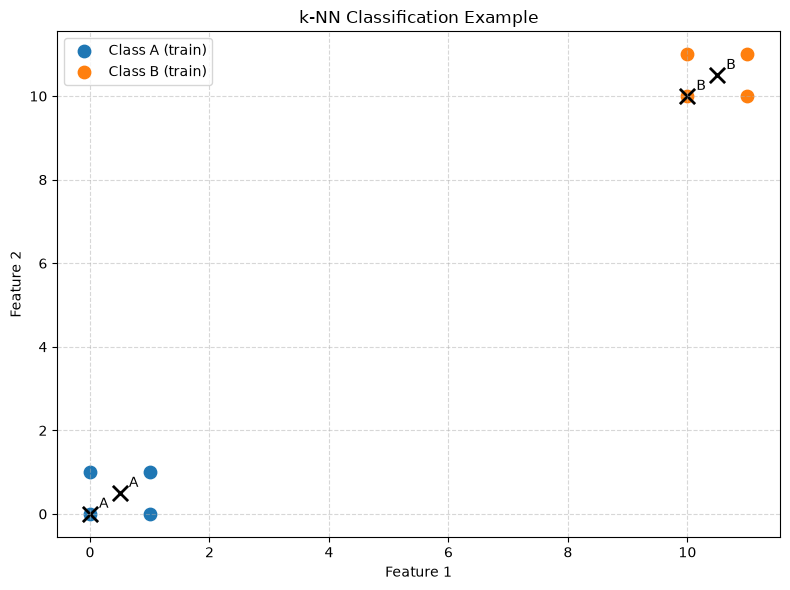

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Plot training samples by class
train_a = X_train[y_train == 'A']
train_b = X_train[y_train == 'B']

plt.scatter(train_a[:, 0], train_a[:, 1], c='tab:blue', s=80, label='Class A (train)')
plt.scatter(train_b[:, 0], train_b[:, 1], c='tab:orange', s=80, label='Class B (train)')

# Plot test samples and their predicted labels
for i, point in enumerate(X_test):
    plt.scatter(point[0], point[1], c='black', marker='x', s=120, linewidths=2)
    plt.text(point[0] + 0.15, point[1] + 0.15, str(predictions[i]), fontsize=10, color='black')

plt.title("k-NN Classification Example")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()